<a href="https://colab.research.google.com/github/AlienXs9/Autism-Facial-Emotion-Recognition-/blob/main/Submission_3_Custom_CNN_Output.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Submission 3 — Custom CNN From Scratch

We build our **own** CNN (no pretrained weights) and train it from zero on 224x224 images.

**Network layout (6 blocks of Conv-BN-ReLU x2 + MaxPool, then a classifier)**

## Step 1 · Imports

In [ ]:
import os, time, zipfile, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


## Step 2 · Settings (change things here)

In [ ]:
ZIP_PATH = "/content/archive.zip"
DATA_DIR = "/content/dataset"

MAX_EPOCHS = 60
MIN_EPOCHS = 5
PATIENCE   = 10
BATCH_SIZE    = 32
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4

DROPOUT  = 0.3
IMG_SIZE = 224
SEED     = 42

use_amp = device.type == "cuda"
torch.manual_seed(SEED); np.random.seed(SEED)
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

## Step 3 · Train, validation, and test split

In [ ]:
if ZIP_PATH and os.path.exists(ZIP_PATH) and not os.path.isdir(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

rows = []
for folder, _, files in os.walk(DATA_DIR):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append((os.path.join(folder, f), os.path.basename(folder)))

df = pd.DataFrame(rows, columns=["path", "class_name"])
class_names = sorted(df["class_name"].unique())
df["label"] = df["class_name"].map({c: i for i, c in enumerate(class_names)})
NUM_CLASSES = len(class_names)

print(len(df), "images,", NUM_CLASSES, "classes:", class_names)
print(df["class_name"].value_counts())

7600 images, 6 classes: ['Natural', 'anger', 'fear', 'joy', 'sadness', 'surprise']
class_name
joy         3500
sadness     2000
anger        690
surprise     630
Natural      480
fear         300
Name: count, dtype: int64


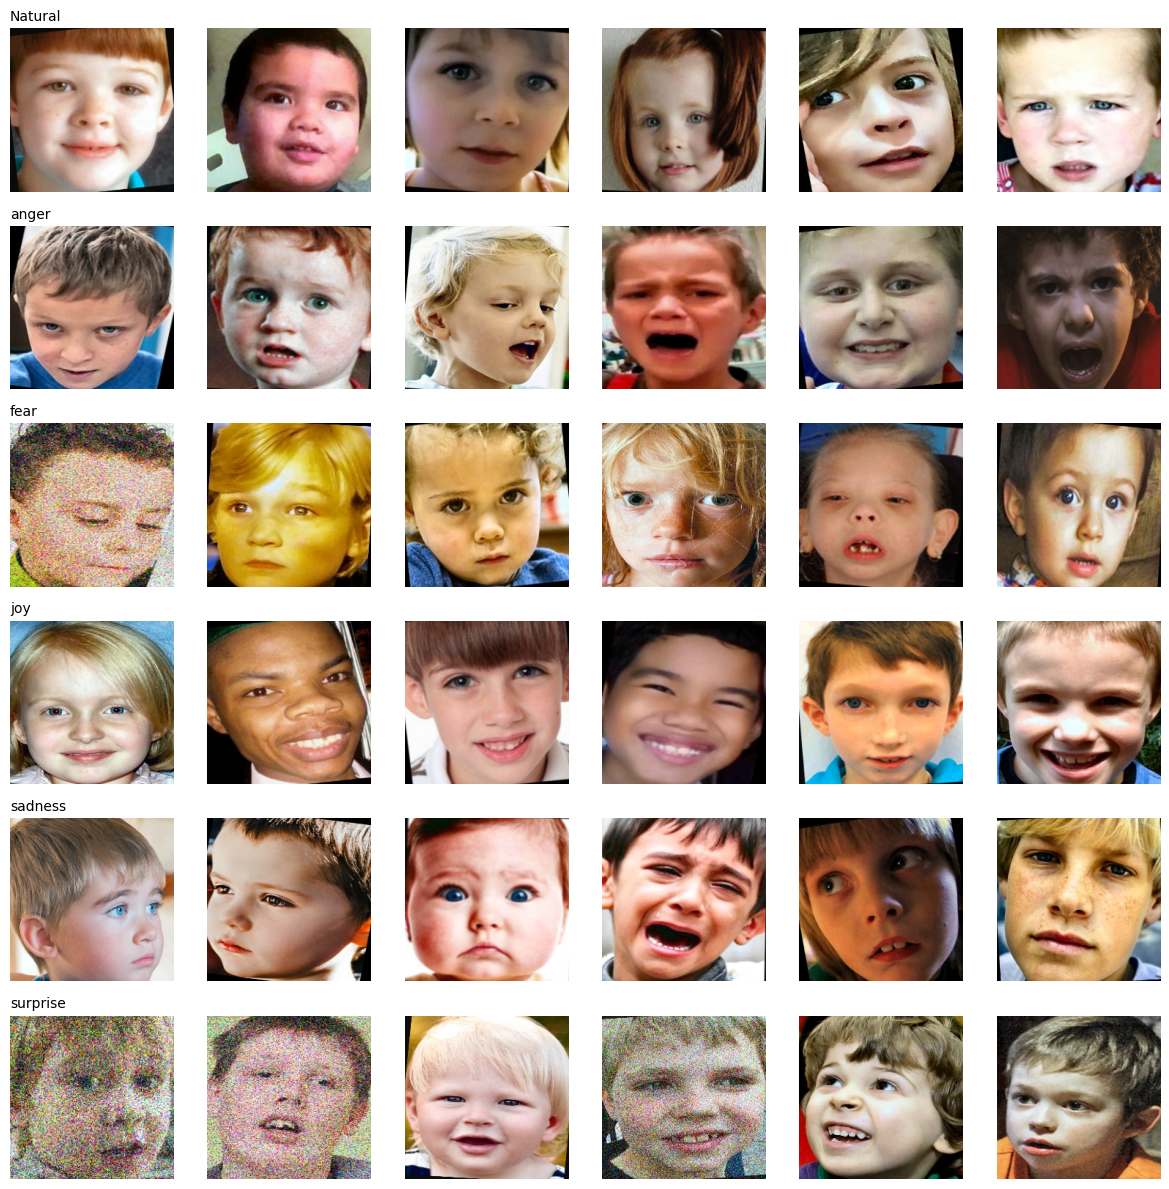

In [ ]:
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(12, 2 * NUM_CLASSES))
for r, cname in enumerate(class_names):
    sample = df[df["class_name"] == cname].sample(6, random_state=SEED)
    for c, (ax, p) in enumerate(zip(axes[r], sample["path"])):
        ax.imshow(Image.open(p).convert("RGB")); ax.axis("off")
        if c == 0:
            ax.set_title(cname, fontsize=10, loc="left")
plt.tight_layout(); plt.show()

In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)
print("train:", len(train_df), "| val:", len(val_df), "| test:", len(test_df))

counts = train_df["label"].value_counts().sort_index().values
class_weights = torch.tensor((len(train_df) / (NUM_CLASSES * counts)) ** 0.5, dtype=torch.float32)
print("class weights:", class_weights.numpy().round(2))

train: 6080 | val: 760 | test: 760
class weights: [1.62 1.35 2.05 0.6  0.8  1.42]


## Step 4 · Preprocessing and augmentation

1. **All images:** resize to 224x224 and normalise pixel values.
2. **Training images only:** random flip, small rotation, small colour change. The model sees a slightly different version of each
  image every epoch, which helps it avoid memorising the training set.

The augmentation is kept light on purpose, so learning from scratch is not slowed down.
We use simple 0.5 / 0.5 normalisation (not ImageNet numbers) because nothing in this model is pretrained.

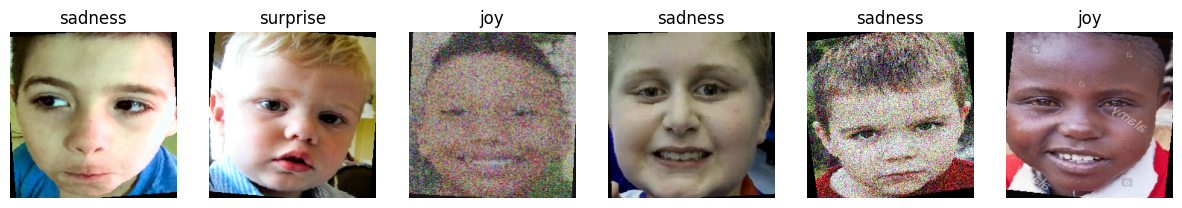

In [ ]:
MEAN, STD = [0.5, 0.5, 0.5], [0.5, 0.5, 0.5]

train_tfm = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tfm = T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

class ImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.paths  = dataframe["path"].tolist()
        self.labels = dataframe["label"].tolist()
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), self.labels[i]

train_loader = DataLoader(ImageDataset(train_df, train_tfm), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(ImageDataset(val_df,   eval_tfm),  batch_size=BATCH_SIZE, num_workers=2)
test_loader  = DataLoader(ImageDataset(test_df,  eval_tfm),  batch_size=BATCH_SIZE, num_workers=2)

imgs, labs = next(iter(train_loader))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, im, lb in zip(axes, imgs, labs):
    im = (im * 0.5 + 0.5).clamp(0, 1)
    ax.imshow(im.permute(1, 2, 0)); ax.set_title(class_names[lb]); ax.axis("off")
plt.show()

## Step 5 · The Custom CNN

Each **block** = Conv -> BatchNorm -> ReLU, twice, then MaxPool. We write it once as a small helper and use it six times. A broad explanation is written in the report.

1. **Conv** finds patterns (edges first, then shapes, then face parts).
2. **Two convs per block** to let the network learn richer patterns before each downsizing, and make each unit "see" more of the image.
3. **BatchNorm** is used to keep the numbers stable so training from scratch works better.
4. **ReLU** adds non-linearity (turns negative values into 0).
5. **MaxPool** halves the image size and keeps the strongest signals.
6. **Dropout** randomly switches off 30% of the numbers during training so the model cannot rely on any single neuron.
7. **Fully Connected (Linear)** turns the final 256 numbers into one score per class.

In [ ]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 256),
            conv_block(256, 256),
            conv_block(256, 256),
        )
        self.pool    = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(DROPOUT)
        self.fc      = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.fc(x)

model = CustomCNN(NUM_CLASSES).to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("\nTrainable parameters:", n_params)

with torch.no_grad():
    print("Output shape:", model.eval()(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=device)).shape)

CustomCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): R

## Step 6 · Training function

Each epoch: learn on the training set, then measure loss/accuracy on the validation set.

1. **Early stopping:** if validation loss has not improved for `PATIENCE` epochs (and at least `MIN_EPOCHS` have run) we stop
  and go back to the best weights.
2. We watch **both** training and validation loss every epoch to catch overfitting (validation loss rising while training loss falls).

In [ ]:
def run_epoch(model, loader, loss_fn, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out  = model(x)
                loss = loss_fn(out, y)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            correct    += (out.argmax(1) == y).sum().item()
            n          += len(y)
    return total_loss / n, correct / n

def train_model(model):
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler    = torch.amp.GradScaler("cuda", enabled=use_amp)
    loss_fn   = nn.CrossEntropyLoss(weight=class_weights.to(device))

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, best_epoch, wait = float("inf"), None, 0, 0

    start = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, loss_fn, optimizer, scaler)
        va_loss, va_acc = run_epoch(model, val_loader, loss_fn)

        history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc);   history["val_acc"].append(va_acc)
        print(f"Epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | val loss {va_loss:.3f} acc {va_acc:.3f}")

        if va_loss < best_val_loss:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            best_weights = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE and epoch >= MIN_EPOCHS:
                print(f"Early stopping at epoch {epoch} (best epoch was {best_epoch}).")
                break

    train_time = time.time() - start
    model.load_state_dict(best_weights)
    return history, train_time, best_epoch

## Step 7 · Train the model

In [ ]:
history, train_time, best_epoch = train_model(model)
print(f"\nTraining time: {train_time:.1f} seconds, epochs run: {len(history['train_loss'])}, best epoch: {best_epoch}")
torch.save(model.state_dict(), "custom_cnn_best.pt")

Epoch  1 | train loss 1.725 acc 0.424 | val loss 1.689 acc 0.445
Epoch  2 | train loss 1.699 acc 0.444 | val loss 1.678 acc 0.425
Epoch  3 | train loss 1.687 acc 0.435 | val loss 1.672 acc 0.437
Epoch  4 | train loss 1.666 acc 0.437 | val loss 1.628 acc 0.455
Epoch  5 | train loss 1.617 acc 0.456 | val loss 1.573 acc 0.508
Epoch  6 | train loss 1.511 acc 0.499 | val loss 1.856 acc 0.518
Epoch  7 | train loss 1.334 acc 0.572 | val loss 1.316 acc 0.532
Epoch  8 | train loss 1.236 acc 0.599 | val loss 1.243 acc 0.591
Epoch  9 | train loss 1.083 acc 0.641 | val loss 1.113 acc 0.667
Epoch 10 | train loss 0.976 acc 0.670 | val loss 1.019 acc 0.664
Epoch 11 | train loss 0.869 acc 0.691 | val loss 0.954 acc 0.655
Epoch 12 | train loss 0.779 acc 0.717 | val loss 0.763 acc 0.707
Epoch 13 | train loss 0.685 acc 0.746 | val loss 0.858 acc 0.717
Epoch 14 | train loss 0.635 acc 0.757 | val loss 0.696 acc 0.736
Epoch 15 | train loss 0.610 acc 0.772 | val loss 0.578 acc 0.776
Epoch 16 | train loss 0.5

## Step 8 · Training curves (train vs validation)


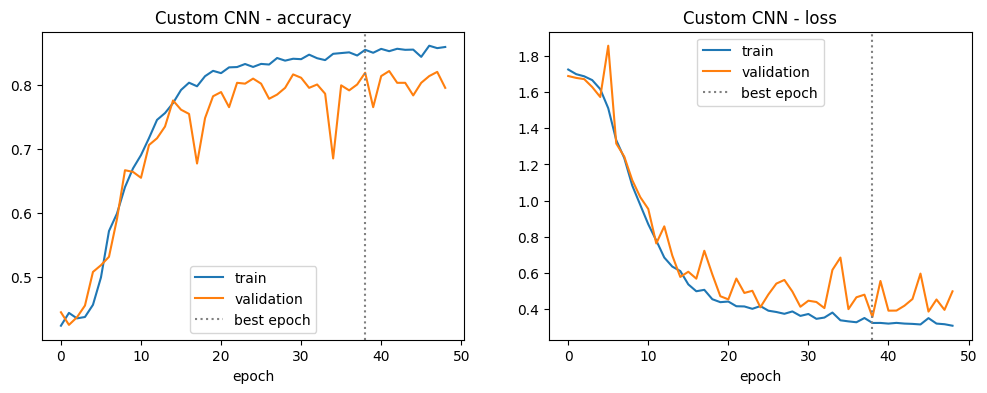

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_acc"], label="train"); ax[0].plot(history["val_acc"], label="validation")
ax[0].axvline(best_epoch - 1, color="gray", linestyle=":", label="best epoch")
ax[0].set_title("Custom CNN - accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["train_loss"], label="train"); ax[1].plot(history["val_loss"], label="validation")
ax[1].axvline(best_epoch - 1, color="gray", linestyle=":", label="best epoch")
ax[1].set_title("Custom CNN - loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## Step 9 · Test-set evaluation

              precision    recall  f1-score   support

     Natural      0.980     1.000     0.990        48
       anger      0.518     0.826     0.637        69
        fear      0.550     0.733     0.629        30
         joy      0.989     0.994     0.991       350
     sadness      0.833     0.575     0.680       200
    surprise      0.803     0.905     0.851        63

    accuracy                          0.851       760
   macro avg      0.779     0.839     0.796       760
weighted avg      0.872     0.851     0.851       760



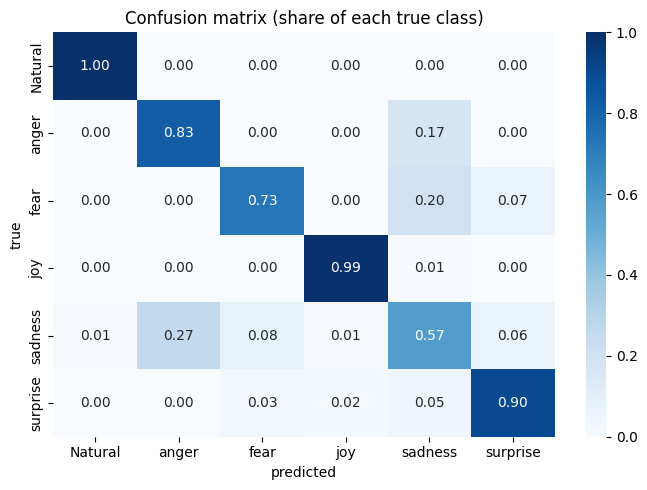

Training time: 1348.9 s | Testing time: 2.70 s


In [ ]:
model.eval()
preds, labels = [], []
start = time.time()
with torch.no_grad(), torch.autocast(device_type=device.type, enabled=use_amp):
    for x, y in test_loader:
        preds  += model(x.to(device)).argmax(1).cpu().tolist()
        labels += y.tolist()
test_time = time.time() - start
labels, preds = np.array(labels), np.array(preds)

print(classification_report(labels, preds, target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(labels, preds, normalize="true")
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix (share of each true class)"); plt.xlabel("predicted"); plt.ylabel("true")
plt.tight_layout(); plt.show()

print(f"Training time: {train_time:.1f} s | Testing time: {test_time:.2f} s")

## Step 10 · Summary (same columns as Submission 2)

In [ ]:
report = classification_report(labels, preds, output_dict=True, zero_division=0)
summary = pd.DataFrame([{
    "Model": "custom_cnn_6_blocks",
    "Epochs run": len(history["train_loss"]),
    "Test accuracy": report["accuracy"],
    "Precision (macro)": report["macro avg"]["precision"],
    "Recall (macro)": report["macro avg"]["recall"],
    "F1 (macro)": report["macro avg"]["f1-score"],
    "Parameters": n_params,
    "Training time (s)": train_time,
    "Testing time (s)": test_time,
}]).round(4)
display(summary)
summary.to_csv("summary_custom_cnn.csv", index=False)

,Model,Epochs run,Test accuracy,Precision (macro),Recall (macro),F1 (macro),Parameters,Training time (s),Testing time (s)
0,custom_cnn_6_blocks,49,0.8513,0.7788,0.8389,0.7963,3536102,1348.9472,2.6999
